# Perceptrón multicapa — Evaluación de desempeño

**Curso:** Inteligencia Artificial y Sistemas Inteligentes — UNIMINUTO  
**Autor:** Alejandro [apellidos]

Cada sección de este notebook corresponde a un paso del reporte. Ejecuta las celdas en orden, de arriba hacia abajo.

## 4.1 Librerías y entorno

Importamos las herramientas que vamos a usar.

In [1]:
# Paso 4.1: Librerías y entorno

import numpy as np                      # cálculos con matrices
import matplotlib.pyplot as plt         # gráficas

# scikit-learn: datos, preprocesamiento y métricas
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             confusion_matrix, classification_report)

# TensorFlow / Keras: la red neuronal
import tensorflow as tf
from tensorflow import keras

# Semilla: hace que los resultados sean reproducibles
SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

print("Python listo")
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

Python listo
NumPy: 2.5.4
TensorFlow: 2.22.0-rc0


## 4.2 Generación de los datos

Creamos un conjunto de datos simulado para un problema de clasificación binaria.

In [ ]:
# Paso 4.2: Generación de los datos

X, y = make_classification(
    n_samples=1000,      # 1000 ejemplos (filas)
    n_features=12,       # 12 variables (columnas)
    n_informative=8,     # 8 variables útiles para predecir
    n_redundant=2,       # 2 variables repetidas (combinación de otras)
    n_classes=2,         # clasificación binaria: clase 0 o 1
    random_state=SEMILLA
)

# Revisemos qué se creó
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Ejemplos por clase:", np.bincount(y))

print("\nPrimeras 3 filas de X:")
print(np.round(X[:3], 2))
print("Sus clases:", y[:3])

Forma de X: (1000, 12)
Forma de y: (1000,)
Ejemplos por clase: [500 500]

Primeras 3 filas de X:
[[ 1.11  1.82  0.99 -1.08  0.02 -4.56 -1.06  0.74 -2.47 -0.77 -1.74  2.12]
 [-0.99 -1.49 -0.16  0.53 -1.7  -3.82 -0.39  2.37 -3.23 -1.72 -2.79  2.52]
 [-1.05 -0.21  0.26 -3.82  0.28 -7.24  1.58  1.73 -3.7  -4.67 -2.2   2.67]]
Sus clases: [0 1 0]


## 4.3 División entrenamiento / prueba

Separamos los datos: unos para que el modelo aprenda y otros para evaluarlo.

In [4]:
# Paso 4.3: División entrenamiento / prueba

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20 % para prueba, 80 % para entrenamiento
    random_state=SEMILLA  # la misma división en cada ejecución
)

print("Entrenamiento:", X_train.shape, "→ clases:", np.bincount(y_train))
print("Prueba:       ", X_test.shape,  "→ clases:", np.bincount(y_test))

Entrenamiento: (800, 12) → clases: [390 410]
Prueba:        (200, 12) → clases: [110  90]


## 4.4 Normalización

Ponemos todas las variables en la misma escala.

In [5]:
# Paso 4.4: Normalización (estandarización)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)  # aprende media y desviación SOLO del entrenamiento
X_test_scaled  = scaler.transform(X_test)       # aplica esas mismas medidas a prueba

np.set_printoptions(suppress=True)  # mostrar números sin notación científica

print("ANTES de normalizar (entrenamiento)")
print("  Media:", np.round(X_train.mean(axis=0), 1))
print("  Desv.:", np.round(X_train.std(axis=0), 1))

print("\nDESPUÉS de normalizar (entrenamiento)")
print("  Media:", np.round(X_train_scaled.mean(axis=0), 1))
print("  Desv.:", np.round(X_train_scaled.std(axis=0), 1))

print("\nPrueba normalizada")
print("  Media:", np.round(X_test_scaled.mean(axis=0), 1))

ANTES de normalizar (entrenamiento)
  Media: [-0.   0.5  0.  -0.  -0.6 -1.7  0.   1.1 -1.5 -1.  -0.6  0.5]
  Desv.: [1.  1.8 1.  1.9 1.9 3.1 2.1 1.6 2.  1.7 1.9 1.8]

DESPUÉS de normalizar (entrenamiento)
  Media: [ 0.  0. -0. -0. -0.  0.  0.  0.  0.  0.  0.  0.]
  Desv.: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Prueba normalizada
  Media: [-0.1  0.1 -0.1 -0.1  0.  -0.1 -0.1  0.  -0.1 -0.1  0.1 -0. ]


## 4.5 Construcción del modelo en Keras

Definimos la arquitectura de la red: capas, neuronas y funciones de activación.

In [6]:
# Paso 4.5: Construcción del modelo (perceptrón multicapa)

modelo = keras.Sequential([
    keras.Input(shape=(12,)),                      # capa de entrada: 12 variables
    keras.layers.Dense(16, activation="relu"),     # capa oculta 1: 16 neuronas
    keras.layers.Dense(8, activation="relu"),      # capa oculta 2: 8 neuronas
    keras.layers.Dense(1, activation="sigmoid")    # capa de salida: 1 neurona (probabilidad)
])

modelo.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

## 4.6 Entrenamiento (retropropagación)

El modelo ajusta sus pesos a partir de los errores.

Época | Pérdida entren. | Pérdida valid. | Accuracy entren. | Accuracy valid.
    1 |          0.7171 |         0.6956 |           0.5203 |          0.5437
   10 |          0.4986 |         0.5306 |           0.7906 |          0.8062
   25 |          0.3357 |         0.3803 |           0.8797 |          0.8438
   50 |          0.2097 |         0.2612 |           0.9328 |          0.8875
  100 |          0.1301 |         0.2283 |           0.9563 |          0.9187
  150 |          0.0905 |         0.2175 |           0.9672 |          0.9125


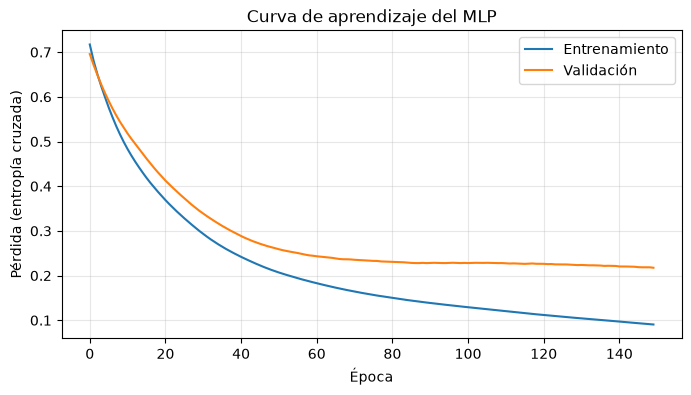

In [7]:
# Paso 4.6: Entrenamiento con retropropagación

# 1) Configurar cómo aprende la red
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),  # método y tamaño del paso
    loss="binary_crossentropy",                            # cómo se mide el error
    metrics=["accuracy"]                                   # qué más queremos ver
)

# 2) Entrenar
historia = modelo.fit(
    X_train_scaled, y_train,
    validation_split=0.2,   # 20 % del entrenamiento para validar en cada época
    epochs=150,             # 150 vueltas completas a los datos
    batch_size=32,          # ajusta los pesos cada 32 ejemplos
    verbose=0               # no imprimir las 150 épocas
)

# 3) Ver cómo evolucionó el aprendizaje en algunas épocas
h = historia.history
print("Época | Pérdida entren. | Pérdida valid. | Accuracy entren. | Accuracy valid.")
for e in [1, 10, 25, 50, 100, 150]:
    i = e - 1
    print(f"{e:5} | {h['loss'][i]:15.4f} | {h['val_loss'][i]:14.4f} | "
          f"{h['accuracy'][i]:16.4f} | {h['val_accuracy'][i]:15.4f}")

# 4) Gráfica: curva de aprendizaje
plt.figure(figsize=(8, 4))
plt.plot(h["loss"], label="Entrenamiento")
plt.plot(h["val_loss"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (entropía cruzada)")
plt.title("Curva de aprendizaje del MLP")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("figuras/curva_aprendizaje.png", dpi=150, bbox_inches="tight")
plt.show()

## 4.7 Evaluación con métricas

Medimos qué tan bien predice con datos que nunca vio.

In [8]:
# Paso 4.7: Evaluación con el conjunto de prueba

# 1) Predecir: probabilidades y luego clases
y_proba = modelo.predict(X_test_scaled, verbose=0).ravel()  # probabilidad de clase 1
y_pred  = (y_proba >= 0.5).astype(int)                      # umbral 0.5 → 0 o 1

print("Primeros 5 ejemplos de prueba")
print("  Probabilidad:", np.round(y_proba[:5], 3))
print("  Predicción:  ", y_pred[:5])
print("  Real:        ", y_test[:5])

# 2) Métricas
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("AUC-ROC: ", round(roc_auc_score(y_test, y_proba), 4))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, digits=3))


Primeros 5 ejemplos de prueba
  Probabilidad: [1.    0.961 0.999 0.85  0.426]
  Predicción:   [1 1 1 1 0]
  Real:         [1 1 1 1 1]

Accuracy: 0.905
AUC-ROC:  0.9753

Matriz de confusión:
[[98 12]
 [ 7 83]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0      0.933     0.891     0.912       110
           1      0.874     0.922     0.897        90

    accuracy                          0.905       200
   macro avg      0.904     0.907     0.904       200
weighted avg      0.906     0.905     0.905       200



## 4.8 Comparación con una red simple

Comparamos el MLP con una red sin capas ocultas.

In [9]:
# Paso 4.8: Comparación con una red simple (sin capas ocultas)

keras.utils.set_random_seed(SEMILLA)  # mismo punto de partida aleatorio

red_simple = keras.Sequential([
    keras.Input(shape=(12,)),
    keras.layers.Dense(1, activation="sigmoid")   # una sola neurona, sin capas ocultas
])
red_simple.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
red_simple.fit(X_train_scaled, y_train, validation_split=0.2,
               epochs=150, batch_size=32, verbose=0)

# Evaluar con los mismos 200 ejemplos de prueba
proba_simple = red_simple.predict(X_test_scaled, verbose=0).ravel()
pred_simple  = (proba_simple >= 0.5).astype(int)

print("Parámetros red simple:", red_simple.count_params())
print("Parámetros MLP:       ", modelo.count_params())
print("\nMatriz de confusión red simple:")
print(confusion_matrix(y_test, pred_simple))

# Tabla comparativa
print("\nModelo       | Accuracy | AUC-ROC")
print(f"MLP          | {accuracy_score(y_test, y_pred):8.3f} | {roc_auc_score(y_test, y_proba):7.3f}")
print(f"Red simple   | {accuracy_score(y_test, pred_simple):8.3f} | {roc_auc_score(y_test, proba_simple):7.3f}")


Parámetros red simple: 13
Parámetros MLP:        353

Matriz de confusión red simple:
[[76 34]
 [29 61]]

Modelo       | Accuracy | AUC-ROC
MLP          |    0.905 |   0.975
Red simple   |    0.685 |   0.743


In [ ]:
# Paso 4.9: Influencia del número de capas y neuronas

def entrenar_red(capas_ocultas):
    """Construye y entrena una red con las capas ocultas indicadas.
    Ejemplo: [16, 8] = dos capas ocultas de 16 y 8 neuronas."""
    keras.utils.set_random_seed(SEMILLA)          # mismo punto de partida para todas

    capas = [keras.Input(shape=(12,))]            # capa de entrada
    for neuronas in capas_ocultas:                # una capa oculta por cada número
        capas.append(keras.layers.Dense(neuronas, activation="relu"))
    capas.append(keras.layers.Dense(1, activation="sigmoid"))  # capa de salida

    red = keras.Sequential(capas)
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                loss="binary_crossentropy", metrics=["accuracy"])
    red.fit(X_train_scaled, y_train, validation_split=0.2,
            epochs=150, batch_size=32, verbose=0)
    return red


# Arquitecturas a comparar: de ninguna capa oculta a tres capas grandes
arquitecturas = [[], [4], [16], [16, 8], [64, 32], [128, 64, 32]]

print("Capas ocultas  | Parámetros | Acc. entren. | Acc. prueba | AUC prueba")
for arq in arquitecturas:
    red = entrenar_red(arq)

    pred_train = (red.predict(X_train_scaled, verbose=0).ravel() >= 0.5).astype(int)
    proba_test = red.predict(X_test_scaled, verbose=0).ravel()
    pred_test  = (proba_test >= 0.5).astype(int)

    acc_train = accuracy_score(y_train, pred_train)
    acc_test  = accuracy_score(y_test, pred_test)
    auc_test  = roc_auc_score(y_test, proba_test)

    nombre = str(arq) if arq else "ninguna"
    print(f"{nombre:14} | {red.count_params():10} | {acc_train:12.3f} | {acc_test:11.3f} | {auc_test:10.3f}")